In [2]:
from pathlib import Path
import sys
import pandas as pd

print("Python:", sys.executable)

raw_dir = Path("../data/raw")
parquet_files = list(raw_dir.glob("*.parquet"))

print("Arquivos encontrados:", parquet_files)

data_path = parquet_files[0]
df = pd.read_parquet(data_path)

print("Arquivo:", data_path.name)
print("Dimensões:", df.shape)

display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Python: c:\Users\marhl\miniconda3\envs\renewable-forecast\python.exe
Arquivos encontrados: [WindowsPath('../data/raw/GERACAO_USINA-2_2026_08.parquet')]
Arquivo: GERACAO_USINA-2_2026_08.parquet
Dimensões: (536712, 12)


,din_instante,id_subsistema,nom_subsistema,id_estado,nom_estado,cod_modalidadeoperacao,nom_tipousina,nom_tipocombustivel,nom_usina,id_ons,ceg,val_geracao
0,2026-08-01,N,NORTE,AM,AMAZONAS,Pequenas Usinas (MMGD),FOTOVOLTAICA,Fotovoltaica,PQU MMAM MMGD,<NA>,-,0.000000
1,2026-08-01,N,NORTE,AM,AMAZONAS,TIPO I,HIDROELÉTRICA,Hidráulica,BALBINA,AMBA,UHE.PH.AM.000190-2.01,78.134925
2,2026-08-01,N,NORTE,AM,AMAZONAS,TIPO I,TÉRMICA,Gás,PIRARUCU,AMPRC,UTE.GN.AM.029432-2.01,68.350500
3,2026-08-01,N,NORTE,AM,AMAZONAS,TIPO I,TÉRMICA,Gás,APARECIDA,AMAA,UTE.GN.AM.027250-7.02,156.937000
4,2026-08-01,N,NORTE,AM,AMAZONAS,TIPO I,TÉRMICA,Gás,UTE AZULAO,AMUTAZ,UTE.GN.AM.035071-0.01,0.000000


,dtype
din_instante,datetime64[ns]
id_subsistema,string
nom_subsistema,string
id_estado,string
nom_estado,string
cod_modalidadeoperacao,string
nom_tipousina,string
nom_tipocombustivel,string
nom_usina,string
id_ons,string


In [3]:
df.isna().sum().sort_values(ascending=False)

id_ons                    87048
val_geracao               63240
din_instante                  0
id_subsistema                 0
id_estado                     0
nom_subsistema                0
nom_estado                    0
cod_modalidadeoperacao        0
nom_tipocombustivel           0
nom_tipousina                 0
nom_usina                     0
ceg                           0
dtype: int64

In [4]:
time_profile = {
    "inicio": df["din_instante"].min(),
    "fim": df["din_instante"].max(),
    "instantes_unicos": df["din_instante"].nunique(),
    "horas_esperadas": int(
        (df["din_instante"].max() - df["din_instante"].min())
        / pd.Timedelta(hours=1)
    ) + 1,
    "minutos_encontrados": sorted(
        df["din_instante"].dt.minute.dropna().unique().tolist()
    ),
}

time_profile

{'inicio': Timestamp('2026-08-01 00:00:00'),
 'fim': Timestamp('2026-08-31 23:00:00'),
 'instantes_unicos': 744,
 'horas_esperadas': 744,
 'minutos_encontrados': [0]}

In [5]:
missing_profile = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": df.isna().mean().mul(100).round(4),
}).sort_values("ausentes", ascending=False)

missing_profile

,ausentes,percentual
id_ons,87048,16.2188
val_geracao,63240,11.7829
din_instante,0,0.0000
id_subsistema,0,0.0000
id_estado,0,0.0000
nom_subsistema,0,0.0000
nom_estado,0,0.0000
cod_modalidadeoperacao,0,0.0000
nom_tipocombustivel,0,0.0000
nom_tipousina,0,0.0000


In [6]:
plant_profile = (
    df.groupby(
        ["cod_modalidadeoperacao", "nom_tipousina"],
        dropna=False
    )
    .size()
    .rename("registros")
    .reset_index()
    .sort_values("registros", ascending=False)
)

plant_profile

,cod_modalidadeoperacao,nom_tipousina,registros
9,TIPO I,HIDROELÉTRICA,113832
0,Conjunto de Usinas,EOLIELÉTRICA,106392
11,TIPO I,TÉRMICA,63408
1,Conjunto de Usinas,FOTOVOLTAICA,60264
3,Pequenas Usinas (MMGD),FOTOVOLTAICA,28272
19,TIPO II-C,TÉRMICA,26040
6,Pequenas Usinas (Tipo III),HIDROELÉTRICA,23064
17,TIPO II-B,TÉRMICA,18600
7,Pequenas Usinas (Tipo III),TÉRMICA,17112
18,TIPO II-C,HIDROELÉTRICA,17112


In [7]:
identified = df[df["id_ons"].notna()].copy()

duplicate_mask = identified.duplicated(
    subset=["din_instante", "id_ons"],
    keep=False
)

print("Duplicações da chave candidata:", duplicate_mask.sum())

display(
    identified.loc[
        duplicate_mask,
        ["din_instante", "id_ons", "nom_usina", "val_geracao"]
    ]
    .sort_values(["id_ons", "din_instante"])
    .head(20)
)

Duplicações da chave candidata: 0


,din_instante,id_ons,nom_usina,val_geracao


In [8]:
sorted(df["nom_tipousina"].dropna().unique())

['EOLIELÉTRICA', 'FOTOVOLTAICA', 'HIDROELÉTRICA', 'NUCLEAR', 'TÉRMICA']

In [9]:
wind = df[
    df["nom_tipousina"].eq("EOLIELÉTRICA")
    & df["id_ons"].notna()
    & ~df["cod_modalidadeoperacao"].eq("Pequenas Usinas (Tipo III)")
].copy()

wind_coverage = (
    wind.groupby(["id_ons", "nom_usina"], as_index=False)
    .agg(
        registros=("din_instante", "size"),
        instantes=("din_instante", "nunique"),
        alvo_ausente=("val_geracao", lambda x: x.isna().sum()),
        percentual_zero=(
            "val_geracao",
            lambda x: round(x.eq(0).mean() * 100, 2)
        ),
        geracao_media=("val_geracao", "mean"),
        geracao_maxima=("val_geracao", "max"),
    )
)

wind_coverage["cobertura_percentual"] = (
    wind_coverage["instantes"]
    .div(df["din_instante"].nunique())
    .mul(100)
    .round(2)
)

wind_candidates = wind_coverage.sort_values(
    [
        "cobertura_percentual",
        "alvo_ausente",
        "percentual_zero",
    ],
    ascending=[False, True, True],
)

display(wind_candidates.head(20))

,id_ons,nom_usina,registros,instantes,alvo_ausente,percentual_zero,geracao_media,geracao_maxima,cobertura_percentual
5,CJU_BA5EIGT,CONJUNTO EÓLICO IGAPORÃ III 500KV,744,744,0,0.0,105.515013,197.8630,100.0
7,CJU_BAARI,CONJUNTO EOLICO ARIZONA,744,744,0,0.0,121.559055,231.5580,100.0
8,CJU_BABAB,CONJUNTO EOLICO BABILONIA,744,744,0,0.0,82.158788,136.5000,100.0
12,CJU_BABW1,CONJUNTO EOLICO BW GUIRAPA I,744,744,0,0.0,33.217969,86.5600,100.0
16,CJU_BACFO,CONJUNTO EOLICO CAMPO FORMOSO,744,744,0,0.0,91.079659,164.6300,100.0
18,CJU_BACRI,CONJUNTO EOLICO CRISTAL,744,744,0,0.0,53.285339,80.7865,100.0
25,CJU_BAE4CLA,CONJUNTO EOLICO CAMPO LARGO,744,744,0,0.0,382.436728,637.8740,100.0
29,CJU_BAGOI,CONJUNTO EOLICO GENTIO DO OURO I,744,744,0,0.0,181.732074,282.0545,100.0
31,CJU_BAIGD,CONJUNTO EOLICO IGAPORA II,744,744,0,0.0,129.822733,289.9455,100.0
42,CJU_BASDB,CONJUNTO EOLICO SERRA DA BABILONIA,744,744,0,0.0,186.295151,371.2450,100.0


### Baseline de Persistência 

In [10]:
asset_id = "CJU_BA5EIGT"

series = (
    df.loc[
        df["id_ons"].eq(asset_id),
        [
            "din_instante",
            "id_ons",
            "nom_usina",
            "cod_modalidadeoperacao",
            "nom_tipousina",
            "val_geracao",
        ],
    ]
    .sort_values("din_instante")
    .reset_index(drop=True)
)

print("Linhas:", len(series))
print("Instantes únicos:", series["din_instante"].nunique())
print("Ausências no alvo:", series["val_geracao"].isna().sum())
print("Duplicações:", series.duplicated(["din_instante", "id_ons"]).sum())
print("Usina:", series["nom_usina"].unique())
print("Modalidade:", series["cod_modalidadeoperacao"].unique())

time_differences = series["din_instante"].diff().dropna()

print("Frequências encontradas:")
display(time_differences.value_counts())

Linhas: 744
Instantes únicos: 744
Ausências no alvo: 0
Duplicações: 0
Usina: <ArrowStringArray>
['CONJUNTO EÓLICO IGAPORÃ III 500KV']
Length: 1, dtype: string
Modalidade: <ArrowStringArray>
['Conjunto de Usinas']
Length: 1, dtype: string
Frequências encontradas:


din_instante
0 days 01:00:00    743
Name: count, dtype: int64

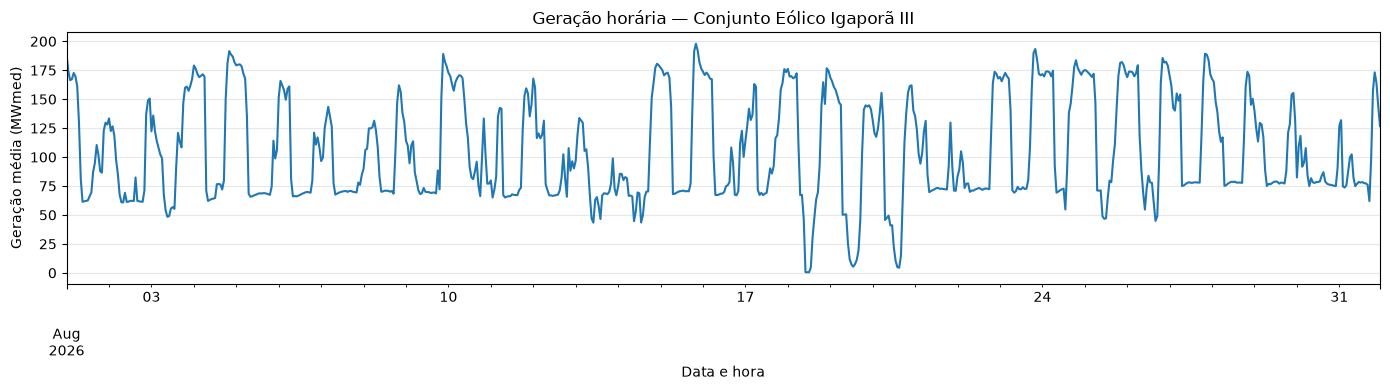

In [11]:
import matplotlib.pyplot as plt

ax = series.plot(
    x="din_instante",
    y="val_geracao",
    figsize=(14, 4),
    legend=False,
    title="Geração horária — Conjunto Eólico Igaporã III",
)

ax.set_xlabel("Data e hora")
ax.set_ylabel("Geração média (MWmed)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
series["pred_persistence_h1"] = series["val_geracao"].shift(1)
series["error"] = (
    series["val_geracao"]
    - series["pred_persistence_h1"]
)
series["absolute_error"] = series["error"].abs()

In [13]:
cutoff = series["din_instante"].max() - pd.Timedelta(days=7)

evaluation = (
    series.loc[
        series["din_instante"] > cutoff
    ]
    .dropna(subset=["pred_persistence_h1"])
    .copy()
)

print("Início da avaliação:", evaluation["din_instante"].min())
print("Fim da avaliação:", evaluation["din_instante"].max())
print("Observações:", len(evaluation))

Início da avaliação: 2026-08-25 00:00:00
Fim da avaliação: 2026-08-31 23:00:00
Observações: 168


In [14]:
mae = evaluation["absolute_error"].mean()
rmse = (evaluation["error"].pow(2).mean()) ** 0.5
bias = evaluation["error"].mean()

print(f"MAE:  {mae:.3f} MWmed")
print(f"RMSE: {rmse:.3f} MWmed")
print(f"Viés: {bias:.3f} MWmed")

MAE:  11.451 MWmed
RMSE: 19.383 MWmed
Viés: -0.282 MWmed


In [15]:
largest_errors = evaluation.nlargest(
    10,
    "absolute_error",
)[
    [
        "din_instante",
        "val_geracao",
        "pred_persistence_h1",
        "error",
        "absolute_error",
    ]
]

display(largest_errors)

,din_instante,val_geracao,pred_persistence_h1,error,absolute_error
631,2026-08-27 07:00:00,74.9655,153.9455,-78.9800,78.9800
583,2026-08-25 07:00:00,71.1225,147.0660,-75.9435,75.9435
619,2026-08-26 19:00:00,164.2405,93.7415,70.4990,70.4990
607,2026-08-26 07:00:00,118.6225,179.3160,-60.6935,60.6935
739,2026-08-31 19:00:00,157.0155,98.7100,58.3055,58.3055
722,2026-08-31 02:00:00,74.7160,131.8745,-57.1585,57.1585
696,2026-08-30 00:00:00,82.3665,131.7830,-49.4165,49.4165
667,2026-08-28 19:00:00,160.8140,113.2745,47.5395,47.5395
643,2026-08-27 19:00:00,164.9895,117.9595,47.0300,47.0300
618,2026-08-26 18:00:00,93.7415,48.7630,44.9785,44.9785


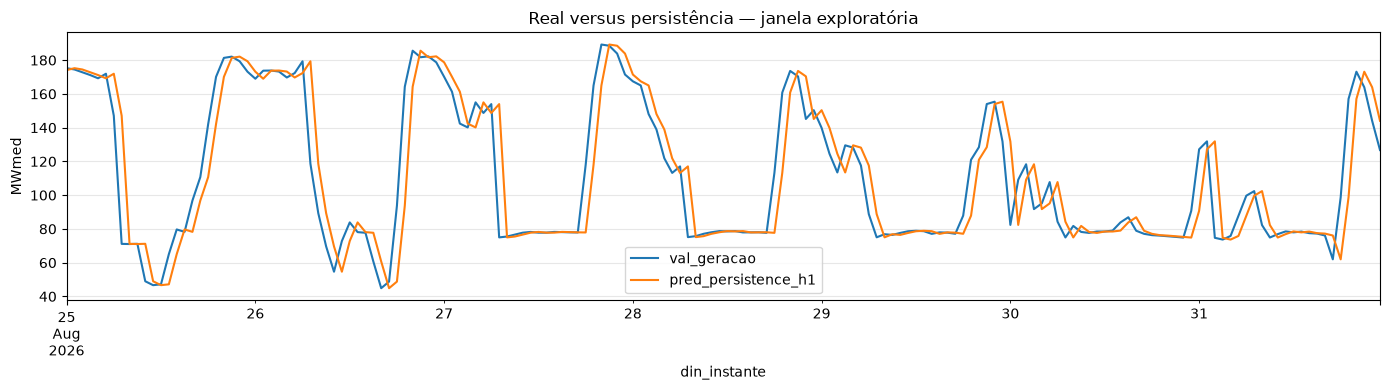

In [16]:
evaluation.plot(
    x="din_instante",
    y=["val_geracao", "pred_persistence_h1"],
    figsize=(14, 4),
    title="Real versus persistência — janela exploratória",
)

plt.ylabel("MWmed")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### baselines sazonais

In [17]:
series["pred_persistence_h1"] = series["val_geracao"].shift(1)
series["pred_seasonal_24h"] = series["val_geracao"].shift(24)
series["pred_seasonal_168h"] = series["val_geracao"].shift(168)

cutoff = series["din_instante"].max() - pd.Timedelta(days=7)

evaluation = (
    series.loc[series["din_instante"] > cutoff]
    .copy()
)

In [18]:
baseline_columns = {
    "persistencia_1h": "pred_persistence_h1",
    "sazonal_24h": "pred_seasonal_24h",
    "sazonal_168h": "pred_seasonal_168h",
}

results = []

for model_name, prediction_column in baseline_columns.items():
    valid = evaluation.dropna(
        subset=["val_geracao", prediction_column]
    ).copy()

    error = valid["val_geracao"] - valid[prediction_column]

    results.append({
        "modelo": model_name,
        "observacoes": len(valid),
        "mae": error.abs().mean(),
        "rmse": (error.pow(2).mean()) ** 0.5,
        "vies": error.mean(),
        "erro_maximo": error.abs().max(),
    })

baseline_metrics = (
    pd.DataFrame(results)
    .sort_values("mae")
    .reset_index(drop=True)
)

persistence_mae = baseline_metrics.loc[
    baseline_metrics["modelo"].eq("persistencia_1h"),
    "mae",
].iloc[0]

baseline_metrics["melhoria_mae_vs_persistencia_pct"] = (
    1 - baseline_metrics["mae"] / persistence_mae
) * 100

display(baseline_metrics.round(3))

,modelo,observacoes,mae,rmse,vies,erro_maximo,melhoria_mae_vs_persistencia_pct
0,persistencia_1h,168,11.451,19.383,-0.282,78.980,0.000
1,sazonal_24h,168,16.852,26.375,-5.374,97.458,-47.162
2,sazonal_168h,168,32.697,43.476,6.139,117.634,-185.529


In [19]:
persistence_evaluation = evaluation.dropna(
    subset=["pred_persistence_h1"]
).copy()

persistence_evaluation["erro"] = (
    persistence_evaluation["val_geracao"]
    - persistence_evaluation["pred_persistence_h1"]
)

persistence_evaluation["erro_absoluto"] = (
    persistence_evaluation["erro"].abs()
)

persistence_evaluation["hora"] = (
    persistence_evaluation["din_instante"].dt.hour
)

hourly_error = (
    persistence_evaluation.groupby("hora")
    .agg(
        observacoes=("erro_absoluto", "size"),
        mae=("erro_absoluto", "mean"),
        erro_maximo=("erro_absoluto", "max"),
        vies=("erro", "mean"),
    )
    .sort_values("mae", ascending=False)
)

display(hourly_error.round(3))

,observacoes,mae,erro_maximo,vies
hora,,,,
19,7,40.676,70.499,40.598
7,7,40.472,78.980,-39.699
18,7,28.615,44.978,28.392
2,7,16.420,57.158,-13.779
0,7,16.320,49.417,-5.580
6,7,15.023,28.801,-7.019
20,7,13.368,24.262,13.269
23,7,12.012,23.594,-6.006
1,7,9.085,26.771,1.272


### Validação

In [20]:
series["hora"] = series["din_instante"].dt.hour
series["delta_1h"] = series["val_geracao"].diff()
series["delta_absoluto_1h"] = series["delta_1h"].abs()

ramp_profile = (
    series.dropna(subset=["delta_1h"])
    .groupby("hora")
    .agg(
        observacoes=("delta_1h", "size"),
        variacao_media=("delta_1h", "mean"),
        variacao_mediana=("delta_1h", "median"),
        variacao_absoluta_media=("delta_absoluto_1h", "mean"),
        maior_rampa_subida=("delta_1h", "max"),
        maior_rampa_descida=("delta_1h", "min"),
    )
    .sort_values("variacao_absoluta_media", ascending=False)
)

display(ramp_profile.round(3))

,observacoes,variacao_media,variacao_mediana,variacao_absoluta_media,maior_rampa_subida,maior_rampa_descida
hora,,,,,,
7,31,-46.102,-46.124,46.299,2.707,-98.558
19,31,23.192,27.971,26.291,70.499,-16.293
18,31,20.995,19.792,25.500,70.897,-27.734
20,31,16.556,11.245,17.092,78.907,-6.557
21,31,4.521,-1.018,15.550,65.661,-36.957
6,31,-10.235,-2.385,14.474,12.291,-66.980
0,30,0.322,-0.489,11.401,45.706,-49.417
2,31,-4.234,-1.630,10.904,25.515,-57.158
22,31,-3.773,-1.845,10.149,30.825,-26.113


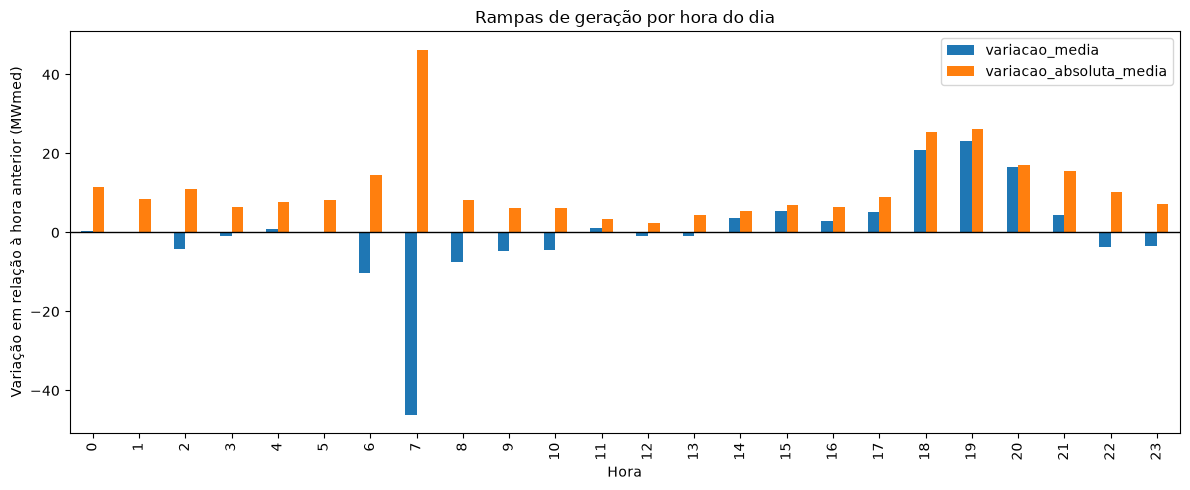

In [21]:
import matplotlib.pyplot as plt

hourly_direction = (
    series.groupby("hora", as_index=False)
    .agg(
        variacao_media=("delta_1h", "mean"),
        variacao_absoluta_media=("delta_absoluto_1h", "mean"),
    )
)

ax = hourly_direction.plot(
    x="hora",
    y=["variacao_media", "variacao_absoluta_media"],
    kind="bar",
    figsize=(12, 5),
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Rampas de geração por hora do dia")
ax.set_xlabel("Hora")
ax.set_ylabel("Variação em relação à hora anterior (MWmed)")
plt.tight_layout()
plt.show()

In [22]:
sign_profile = (
    series.dropna(subset=["delta_1h"])
    .groupby("hora")
    .agg(
        observacoes=("delta_1h", "size"),
        quedas=("delta_1h", lambda x: (x < 0).sum()),
        subidas=("delta_1h", lambda x: (x > 0).sum()),
        sem_variacao=("delta_1h", lambda x: (x == 0).sum()),
    )
)

sign_profile["percentual_quedas"] = (
    sign_profile["quedas"] / sign_profile["observacoes"] * 100
)

sign_profile["percentual_subidas"] = (
    sign_profile["subidas"] / sign_profile["observacoes"] * 100
)

display(sign_profile.loc[[6, 7, 8, 18, 19, 20]].round(2))


,observacoes,quedas,subidas,sem_variacao,percentual_quedas,percentual_subidas
hora,,,,,,
6,31,19,12,0,61.29,38.71
7,31,29,2,0,93.55,6.45
8,31,22,9,0,70.97,29.03
18,31,12,19,0,38.71,61.29
19,31,8,23,0,25.81,74.19
20,31,4,27,0,12.90,87.10


In [23]:
transicoes_7h = series.loc[
    series["hora"].eq(7),
    ["din_instante", "val_geracao", "delta_1h"]
].copy()

display(transicoes_7h)

,din_instante,val_geracao,delta_1h
7,2026-08-01 07:00:00,129.3635,-31.7805
31,2026-08-02 07:00:00,60.9240,-6.5775
55,2026-08-03 07:00:00,67.3165,-31.6130
79,2026-08-04 07:00:00,70.9295,-98.5585
103,2026-08-05 07:00:00,68.2195,-67.1450
127,2026-08-06 07:00:00,80.8300,-80.1795
151,2026-08-07 07:00:00,77.5615,-48.8270
175,2026-08-08 07:00:00,122.9720,-8.4275
199,2026-08-09 07:00:00,71.2085,-7.9750
223,2026-08-10 07:00:00,170.3570,-0.2575
